# Baseline Evaluation — MASSIVE-Agents

Evaluasi pemilihan fungsi dan argumen pada data en-US dan id-ID menggunakan Qwen2.5-7B, Gemma 2 9B, dan Sahabat-AI 9B. Semua model menerima katalog 55 fungsi. Penilaian menggunakan *exact match* internal terhadap ground truth (GT) yang tidak diubah.

## 1. Konfigurasi eksperimen

Mode `development_full` menggunakan 10 ID pada dua bahasa (20 record). Mode `development_full` menggunakan seluruh 979 record development. Mode pengujian diatur hanya pada cell berikut; data test tidak diproses dalam notebook ini.

Pengujian dengan konfigurasi yang sama dapat dijalankan kembali. Hasil yang sudah tersimpan akan dilewati.

In [23]:
import csv
import hashlib
import json
import sys
import time
import urllib.error
import urllib.request
from collections import Counter
from datetime import datetime, timezone
from pathlib import Path

from IPython.display import display

# Pilih mode pengujian: development_full atau development_full.
RUN_MODE = "development_full"

MODELS = [
    "qwen2.5:7b-instruct",
    "gemma2:9b-instruct-q4_K_M",
    "Supa-AI/gemma2-9b-cpt-sahabatai-v1-instruct:q4_k_m",
]

API_BASE = "http://127.0.0.1:11434"
SEED = 20261020
TIMEOUT_SECONDS = 1200
KEEP_ALIVE = "5m"
PROMPT_VERSION = "compact_catalog_v1"
SCORING_VERSION = "internal_exact_match_v1"
OPTIONS = {
    "temperature": 0,
    "seed": SEED,
    "num_ctx": 16384,
    "num_predict": 384,
    "num_batch": 128,
}

PILOT_IDS = [
    "10093", "11598", "1913", "13907", "1803",
    "2263", "3809", "14601", "5243", "2206",
]

if RUN_MODE not in {"pilot_20", "development_full"}:
    raise ValueError("RUN_MODE tidak valid.")

print("Mode:", RUN_MODE)
print("Model:", len(MODELS))
print("Python:", sys.version.split()[0])

Mode: development_full
Model: 3
Python: 3.13.12


## 2. Dataset

Data bersumber dari `data/processed/massive_agents_reviewed`. Jumlah record dibandingkan dengan `finalization_summary.json`. Keputusan audit manual pada tahap preprocessing masih berstatus sementara (*provisional*).

In [24]:
def locate_project():
    current = Path.cwd().resolve()
    for root in [current, *current.parents, Path(r"D:\KP-Agentic-AI")]:
        if (root / "data" / "processed" / "massive_agents_reviewed").is_dir():
            return root
    raise FileNotFoundError("Folder proyek KP-Agentic-AI tidak ditemukan.")

ROOT = locate_project()
DATA_DIR = ROOT / "data" / "processed" / "massive_agents_reviewed"
REPORT_PATH = ROOT / "results" / "preprocessing_reviewed" / "finalization_summary.json"
OUT = ROOT / "results" / "baseline_evaluation"
OUT.mkdir(parents=True, exist_ok=True)

if not REPORT_PATH.exists():
    raise FileNotFoundError(f"Laporan preprocessing tidak ditemukan: {REPORT_PATH}")
review_summary = json.loads(REPORT_PATH.read_text(encoding="utf-8-sig"))
if review_summary.get("anti_leakage_group_and_id") != "PASS":
    raise ValueError("Pemeriksaan anti-leakage belum PASS.")
if review_summary.get("gt_modified") is not False:
    raise ValueError("Status perubahan GT perlu diperiksa.")


def read_jsonl(path):
    if not path.is_file():
        raise FileNotFoundError(f"File dataset tidak ditemukan: {path}")
    rows = []
    required = {
        "row_key", "source_record_id", "language_code", "group_id",
        "split", "question", "function", "gt",
    }
    with path.open("r", encoding="utf-8-sig") as file:
        for line_number, line in enumerate(file, 1):
            if not line.strip():
                continue
            record = json.loads(line)
            missing = required - set(record)
            if missing:
                raise ValueError(f"{path.name}, baris {line_number}: {sorted(missing)}")
            if not isinstance(record["question"], str):
                raise ValueError(f"Pertanyaan bukan string: {record['row_key']}")
            functions = record["function"]
            if not isinstance(functions, list) or len(functions) != 55:
                raise ValueError(f"Katalog fungsi bukan 55: {record['row_key']}")
            names = [item.get("name") for item in functions]
            if len(set(names)) != 55 or not all(isinstance(x, str) for x in names):
                raise ValueError(f"Nama fungsi tidak valid: {record['row_key']}")
            gt = record["gt"]
            if not isinstance(gt, dict) or len(gt) != 1:
                raise ValueError(f"GT tidak valid: {record['row_key']}")
            if next(iter(gt)) not in names:
                raise ValueError(f"GT tidak terdapat dalam katalog: {record['row_key']}")
            rows.append(record)
    return rows


dataset = {
    language: read_jsonl(DATA_DIR / f"{language}_development.jsonl")
    for language in ("en-US", "id-ID")
}
all_rows = [record for records in dataset.values() for record in records]
if len({record["row_key"] for record in all_rows}) != len(all_rows):
    raise ValueError("Ditemukan row_key duplikat.")
if any(record["split"] != "development" for record in all_rows):
    raise ValueError("Dataset berisi record di luar development.")
if any(record["language_code"] != language for language, records in dataset.items() for record in records):
    raise ValueError("Label bahasa tidak sesuai.")
if len(all_rows) != review_summary.get("development"):
    raise ValueError("Jumlah development berbeda dari ringkasan preprocessing.")

print("Proyek:", ROOT)
print("Development en-US:", len(dataset["en-US"]))
print("Development id-ID:", len(dataset["id-ID"]))
print("Total:", len(all_rows))
print("Status audit:", review_summary.get("audit_status", "tidak tersedia"))

Proyek: D:\KP-Agentic-AI
Development en-US: 582
Development id-ID: 397
Total: 979
Status audit: provisional decisions; methodological/source verification still required


## 3. Data pengujian

Pilot memakai sepuluh pasangan ID yang telah dipilih sebelumnya, dengan fungsi target berbeda. Pengujian development penuh mencakup semua record pada split development. Pemilihan ID tidak menyatakan bahwa nilai entitas pada kedua bahasa identik.

In [25]:
def target_name(record):
    return next(iter(record["gt"]))


if RUN_MODE == "pilot_20":
    index = {
        language: {str(record["source_record_id"]): record for record in records}
        for language, records in dataset.items()
    }
    selected = []
    for record_id in PILOT_IDS:
        if record_id not in index["en-US"] or record_id not in index["id-ID"]:
            raise ValueError(f"Pasangan ID {record_id} tidak ditemukan pada development.")
        en = index["en-US"][record_id]
        ind = index["id-ID"][record_id]
        if target_name(en) != target_name(ind):
            raise ValueError(f"Fungsi target berbeda pada pasangan {record_id}.")
        selected.extend([en, ind])
    if len({target_name(record) for record in selected}) != 10:
        raise ValueError("Pilot harus mencakup 10 fungsi target berbeda.")
else:
    selected = sorted(
        all_rows, key=lambda record: (str(record["source_record_id"]), record["language_code"])
    )

if len({record["row_key"] for record in selected}) != len(selected):
    raise ValueError("Duplikasi record terpilih.")

print("Record:", len(selected))
print("Total permintaan:", len(selected) * len(MODELS))
for record in selected[:6]:
    print(record["source_record_id"], record["language_code"], target_name(record))

expected = 979 if RUN_MODE == "development_full" else 20
assert len(selected) == expected, (
    f"Jumlah record salah: {len(selected)}, seharusnya {expected}"
)

Record: 979
Total permintaan: 2937
10038 en-US cooking.recipe
10038 id-ID cooking.recipe
10048 en-US cooking.recipe
1007 en-US play.music
1007 id-ID play.music
10080 en-US cooking.recipe


## 4. Prompt dan format respons

Prompt V1 menampilkan nama fungsi, ringkasan deskripsi, dan nama parameter untuk semua 55 fungsi. Model diminta menghasilkan JSON dengan `name` dan `arguments`. Versi prompt sama dengan pilot 20 record sebelumnya.

Qwen2.5 dan Gemma 2 menggunakan `/api/chat` dengan `format=json`. Sahabat-AI menggunakan `/api/generate` dengan format prompt Gemma 2 karena kebutuhan template model lokal. Perbedaan transport dicatat dalam konfigurasi eksperimen.

In [26]:
def compact_json(value):
    return json.dumps(value, ensure_ascii=False, separators=(",", ":"))


def compact_catalog(record):
    lines = []
    for func in record["function"]:
        description = func.get("description", "")
        description = description.split("The default user experience")[0]
        description = description.split(". ")[0].strip()[:100]
        properties = func.get("parameters", {}).get("properties", {})
        arguments = ", ".join(properties.keys())
        lines.append(
            f"{func['name']}: {description}\n"
            f"  Arguments: {arguments if arguments else 'none'}"
        )
    return "\n".join(lines)


def compact_prompt(record):
    return (
        "Select the most appropriate function for the user request.\n"
        "Return one JSON object with exactly two keys: name and arguments.\n"
        "The name must be a function from the catalog.\n"
        "Arguments must contain the relevant parameter names and string values.\n"
        "Do not copy function definitions or include explanations.\n\n"
        "Available functions:\n"
        + compact_catalog(record)
        + "\n\nUser request:\n"
        + record["question"]
        + '\n\nJSON output: {"name":"function_name","arguments":{}}'
    )


def build_request(model, record):
    content = compact_prompt(record)
    payload = {
        "model": model,
        "stream": False,
        "options": dict(OPTIONS),
        "keep_alive": KEEP_ALIVE,
    }
    if model.startswith("Supa-AI/"):
        payload["prompt"] = (
            "<start_of_turn>user\n"
            + content
            + "\n<end_of_turn>\n"
            + "<start_of_turn>model\n"
        )
        payload["raw"] = True
        payload["options"]["stop"] = ["<end_of_turn>", "<eos>"]
        return "/api/generate", payload
    payload["messages"] = [{"role": "user", "content": content}]
    payload["format"] = "json"
    return "/api/chat", payload


print("Panjang contoh prompt:", len(compact_prompt(selected[0])))
print("Jumlah fungsi:", len(selected[0]["function"]))

Panjang contoh prompt: 6994
Jumlah fungsi: 55


## 5. Penilaian

Penilaian memeriksa validitas struktur, kesesuaian fungsi, nama parameter, dan nilai parameter. Nilai GT dibandingkan setelah normalisasi kapitalisasi dan spasi. Nilai kosong pada GT memperbolehkan parameter tidak disertakan.

Metrik ini adalah *exact match* internal, bukan AST Accuracy resmi. Parafrasa argumen tetap dihitung berbeda apabila teksnya tidak sesuai GT.

In [27]:
def normalize_value(value):
    return " ".join(value.split()).casefold()


def parse_model_json(raw):
    try:
        obj = json.loads(raw)
    except (json.JSONDecodeError, TypeError):
        return None, "invalid_json"
    if not isinstance(obj, dict):
        return None, "invalid_structure"
    if not isinstance(obj.get("name"), str) or not isinstance(obj.get("arguments"), dict):
        return None, "invalid_structure"
    return obj, "parsed"


def score_internal(prediction, parsing, gt):
    if parsing != "parsed":
        return parsing, False, False

    function_name, gold_args = next(iter(gt.items()))
    if prediction["name"] != function_name:
        return "wrong_function", False, False

    predicted_args = prediction["arguments"]
    gold_keys = set(gold_args)
    if set(predicted_args) - gold_keys:
        return "wrong_argument_keys", True, False

    mandatory = {
        key for key, alternatives in gold_args.items()
        if "" not in alternatives
    }
    if mandatory - set(predicted_args):
        return "wrong_argument_keys", True, False

    for key, value in predicted_args.items():
        allowed = gold_args[key]
        if not isinstance(value, str) or not isinstance(allowed, list):
            return "wrong_argument_values", True, False
        if normalize_value(value) not in {
            normalize_value(str(item)) for item in allowed
        }:
            return "wrong_argument_values", True, False

    return "correct", True, True


sample_gt = {"demo.tool": {"city": ["Jakarta"], "date": ["", "today"]}}
assert score_internal({"name": "demo.tool", "arguments": {"city": "Jakarta"}}, "parsed", sample_gt)[0] == "correct"
assert score_internal({"name": "other", "arguments": {}}, "parsed", sample_gt)[0] == "wrong_function"
assert score_internal({"name": "demo.tool", "arguments": {}}, "parsed", sample_gt)[0] == "wrong_argument_keys"
assert score_internal({"name": "demo.tool", "arguments": {"city": "Bandung"}}, "parsed", sample_gt)[0] == "wrong_argument_values"
assert parse_model_json('{"name":"demo.tool","city":"Jakarta"}')[1] == "invalid_structure"
print("Pemeriksaan scoring: LULUS")

Pemeriksaan scoring: LULUS


## 6. Pemeriksaan model Ollama

Identitas model yang terpasang diperiksa sebelum inferensi. Model yang tidak tersedia menghentikan proses sebelum hasil baru ditulis.

In [28]:
def ollama_request(endpoint, payload=None, timeout=TIMEOUT_SECONDS):
    data = None if payload is None else json.dumps(payload, ensure_ascii=False).encode("utf-8")
    request = urllib.request.Request(
        API_BASE + endpoint,
        data=data,
        headers={"Content-Type": "application/json"},
        method="POST" if data is not None else "GET",
    )
    try:
        with urllib.request.urlopen(request, timeout=timeout) as response:
            return json.loads(response.read().decode("utf-8"))
    except urllib.error.HTTPError as exc:
        detail = exc.read().decode("utf-8", errors="replace")[:800]
        raise RuntimeError(f"HTTP {exc.code}: {detail}") from exc


try:
    tags = ollama_request("/api/tags", timeout=20)
except Exception as exc:
    raise RuntimeError("Ollama tidak dapat diakses. Pastikan 'ollama serve' sudah aktif.") from exc

installed = {item.get("name"): item for item in tags.get("models", [])}
missing = [model for model in MODELS if model not in installed]
if missing:
    raise RuntimeError(f"Model belum tersedia: {missing}")

for model in MODELS:
    print(model, "| digest:", installed[model].get("digest", "")[:12])

qwen2.5:7b-instruct | digest: 845dbda0ea48
gemma2:9b-instruct-q4_K_M | digest: c20bec88025f
Supa-AI/gemma2-9b-cpt-sahabatai-v1-instruct:q4_k_m | digest: 6510227e6320


## 7. Pelaksanaan baseline

Setiap prediksi langsung dicatat ke CSV. Fingerprint menggabungkan prompt, data terpilih, opsi inferensi, dan identitas model. Jika konfigurasi tidak cocok dengan hasil tersimpan, proses dihentikan agar hasil dari eksperimen berbeda tidak tercampur.

Hasil dengan status selain `correct` tetap disimpan untuk analisis kesalahan.

In [29]:
# Nama output terpisah untuk setiap mode.
# Nama output sesuai mode pengujian
run_name = (
    "development_full_v1_verified"
    if RUN_MODE == "development_full"
    else "pilot20_v1"
)

RESULT_FILE = OUT / f"predictions_{run_name}.csv"
CONFIG_FILE = OUT / f"config_{run_name}.json"
SUMMARY_FILE = OUT / f"summary_{run_name}.csv"

# Fingerprint input dan prompt.
dataset_digest = hashlib.sha256()
prompt_digest = hashlib.sha256()
for record in selected:
    dataset_digest.update(compact_json({
        "row_key": record["row_key"], "question": record["question"],
        "function": record["function"], "gt": record["gt"],
    }).encode("utf-8"))
    dataset_digest.update(b"\n")
    prompt_digest.update(compact_prompt(record).encode("utf-8"))
    prompt_digest.update(b"\n")

identity = {
    "run_mode": RUN_MODE,
    "prompt_version": PROMPT_VERSION,
    "scoring_version": SCORING_VERSION,
    "prompt_sha256": prompt_digest.hexdigest(),
    "dataset_sha256": dataset_digest.hexdigest(),
    "record_keys": [record["row_key"] for record in selected],
    "models": MODELS,
    "model_digests": {m: installed[m].get("digest") for m in MODELS},
    "options": OPTIONS,
    "keep_alive": KEEP_ALIVE,
    "api_base": API_BASE,
    "model_transport": {
        m: ("raw_gemma2_prompt" if m.startswith("Supa-AI/") else "chat_json")
        for m in MODELS
    },
}
fingerprint = hashlib.sha256(compact_json(identity).encode("utf-8")).hexdigest()[:20]
config = {
    **identity, "fingerprint": fingerprint,
    "records": len(selected), "requests": len(selected) * len(MODELS),
    "dataset_audit_status": review_summary.get("audit_status"),
    "scoring_note": "Internal exact match; bukan AST Accuracy resmi",
}

FIELDS = [
    "fingerprint", "model", "row_key", "record_id", "language_code",
    "group_id", "target_function", "prediction_name",
    "prediction_arguments_json", "status", "parsed_json", "function_correct",
    "full_match", "done_reason", "prompt_tokens", "output_tokens",
    "latency_seconds", "raw_output", "error", "timestamp_utc",
]

# Periksa file sebelum menulis hasil.
if CONFIG_FILE.exists():
    stored_config = json.loads(CONFIG_FILE.read_text(encoding="utf-8-sig"))
    if stored_config.get("fingerprint") != fingerprint:
        raise RuntimeError(
            f"Konfigurasi berbeda dari {CONFIG_FILE.name}. "
            "Jangan gabungkan hasil; gunakan nama eksperimen terpisah."
        )
elif RESULT_FILE.exists():
    raise RuntimeError(f"{RESULT_FILE.name} sudah ada tanpa file konfigurasi. Data tidak diubah.")
else:
    temp_config = CONFIG_FILE.with_suffix(".tmp")
    temp_config.write_text(json.dumps(config, indent=2, ensure_ascii=False), encoding="utf-8")
    temp_config.replace(CONFIG_FILE)

existing = []
if RESULT_FILE.exists():
    with RESULT_FILE.open("r", encoding="utf-8-sig", newline="") as file:
        reader = csv.DictReader(file)
        if reader.fieldnames != FIELDS:
            raise RuntimeError("Format CSV tersimpan berbeda; data tidak diubah.")
        existing = list(reader)

for row in existing:
    if row.get("fingerprint") != fingerprint:
        raise RuntimeError("Fingerprint hasil sebelumnya tidak sesuai; data tidak diubah.")
    if not row.get("model") or not row.get("row_key") or not row.get("status"):
        raise RuntimeError("Terdapat baris hasil tidak lengkap; periksa CSV terlebih dahulu.")

completed = {(row["model"], row["row_key"]) for row in existing}
if len(completed) != len(existing):
    raise RuntimeError("Terdapat hasil duplikat pada CSV tersimpan.")

print("Fingerprint:", fingerprint)
print("Hasil tersedia:", len(existing))
print("Sisa permintaan:", len(selected) * len(MODELS) - len(completed))

for model in MODELS:
    print("\nMODEL:", model)
    for index, record in enumerate(selected, 1):
        key = (model, record["row_key"])
        if key in completed:
            continue

        endpoint, payload = build_request(model, record)
        response = {}
        raw = ""
        error = ""
        prediction = None
        parsing = "invalid_json"
        status = "api_error"
        fn_ok = False
        full_ok = False
        started = time.perf_counter()

        try:
            response = ollama_request(endpoint, payload)
            raw = (
                response.get("response", "")
                if endpoint == "/api/generate"
                else (response.get("message") or {}).get("content", "")
            )
            prediction, parsing = parse_model_json(raw)
            status, fn_ok, full_ok = score_internal(prediction, parsing, record["gt"])
            if response.get("done_reason") == "length" and status != "correct":
                status = "output_truncated"
        except Exception as exc:
            error = str(exc)[:1000]
            status = "api_error"

        entry = {
            "fingerprint": fingerprint,
            "model": model,
            "row_key": record["row_key"],
            "record_id": record["source_record_id"],
            "language_code": record["language_code"],
            "group_id": record["group_id"],
            "target_function": target_name(record),
            "prediction_name": prediction.get("name", "") if isinstance(prediction, dict) else "",
            "prediction_arguments_json": (
                compact_json(prediction["arguments"])
                if isinstance(prediction, dict) and isinstance(prediction.get("arguments"), dict)
                else ""
            ),
            "status": status,
            "parsed_json": parsing == "parsed",
            "function_correct": fn_ok,
            "full_match": full_ok,
            "done_reason": response.get("done_reason", ""),
            "prompt_tokens": response.get("prompt_eval_count", ""),
            "output_tokens": response.get("eval_count", ""),
            "latency_seconds": round(time.perf_counter() - started, 2),
            "raw_output": raw or "",
            "error": error,
            "timestamp_utc": datetime.now(timezone.utc).isoformat(timespec="seconds"),
        }

        # Simpan hasil per permintaan agar dapat dilanjutkan.
        with RESULT_FILE.open("a", encoding="utf-8", newline="") as file:
            writer = csv.DictWriter(file, fieldnames=FIELDS)
            if file.tell() == 0:
                writer.writeheader()
            writer.writerow(entry)

        existing.append(entry)
        completed.add(key)
        print(f"  {index}/{len(selected)} | {record['row_key']} | {status}")
        if error:
            print("  Error:", error[:200])
        if isinstance(response.get("prompt_eval_count"), int):
            if response["prompt_eval_count"] >= OPTIONS["num_ctx"] - OPTIONS["num_predict"]:
                print("  Peringatan: prompt mendekati batas konteks.")

    try:
        ollama_request("/api/generate", {"model": model, "keep_alive": 0}, timeout=60)
    except Exception:
        pass

print("\nHasil:", RESULT_FILE)
print("Jumlah tersimpan:", len(existing))

Fingerprint: 7c792abe11a3c5b0e1ed
Hasil tersedia: 0
Sisa permintaan: 2937

MODEL: qwen2.5:7b-instruct
  1/979 | en-US:0001206 | wrong_argument_values
  2/979 | id-ID:0000822 | wrong_argument_values
  3/979 | en-US:0001208 | wrong_function
  4/979 | en-US:0000131 | wrong_argument_keys
  5/979 | id-ID:0000092 | wrong_argument_keys
  6/979 | en-US:0001214 | correct
  7/979 | id-ID:0000828 | correct
  8/979 | en-US:0001217 | correct
  9/979 | id-ID:0000831 | correct
  10/979 | en-US:0001219 | correct
  11/979 | en-US:0001222 | correct
  12/979 | id-ID:0000835 | correct
  13/979 | en-US:0001225 | correct
  14/979 | id-ID:0000837 | wrong_argument_values
  15/979 | en-US:0001226 | correct
  16/979 | id-ID:0000838 | correct
  17/979 | en-US:0001228 | correct
  18/979 | id-ID:0000839 | correct
  19/979 | en-US:0001229 | correct
  20/979 | en-US:0001236 | correct
  21/979 | en-US:0000133 | wrong_argument_values
  22/979 | en-US:0001247 | correct
  23/979 | id-ID:0000849 | wrong_function
  24/979

## 8. Ringkasan hasil

Hasil dihitung per model dan bahasa. Ketepatan fungsi dihitung dari pilihan fungsi GT; *full match* memerlukan kesesuaian fungsi serta argumen. Ringkasan pilot merupakan pemeriksaan pipeline, bukan estimasi akurasi keseluruhan dataset.

In [30]:
def as_bool(value):
    return value is True or str(value).lower() == "true"


STATUSES = [
    "correct", "wrong_function", "wrong_argument_keys", "wrong_argument_values",
    "invalid_json", "invalid_structure", "output_truncated", "api_error",
]

summary_rows = []
for model in MODELS:
    for language in ("en-US", "id-ID"):
        rows = [
            row for row in existing
            if row["model"] == model and row["language_code"] == language
        ]
        if not rows:
            continue
        counts = Counter(row["status"] for row in rows)
        total = len(rows)
        summary_rows.append({
            "model": model,
            "language_code": language,
            "total": total,
            "format_valid_rate": round(sum(as_bool(row["parsed_json"]) for row in rows) / total, 4),
            "function_accuracy": round(sum(as_bool(row["function_correct"]) for row in rows) / total, 4),
            "full_match_rate_internal": round(sum(as_bool(row["full_match"]) for row in rows) / total, 4),
            **{f"n_{status}": counts.get(status, 0) for status in STATUSES},
        })

if not summary_rows:
    raise RuntimeError("Belum ada hasil untuk diringkas.")

summary_temp = SUMMARY_FILE.with_suffix(".tmp")
with summary_temp.open("w", encoding="utf-8-sig", newline="") as file:
    writer = csv.DictWriter(file, fieldnames=list(summary_rows[0]))
    writer.writeheader()
    writer.writerows(summary_rows)
summary_temp.replace(SUMMARY_FILE)

try:
    import pandas as pd
    display(pd.DataFrame(summary_rows))
except ImportError:
    for row in summary_rows:
        print(row)

print("Total hasil:", len(existing), "/", len(selected) * len(MODELS))
print("Status:", dict(Counter(row["status"] for row in existing)))
print("CSV prediksi:", RESULT_FILE)
print("CSV ringkasan:", SUMMARY_FILE)
print("Konfigurasi:", CONFIG_FILE)

,model,language_code,total,format_valid_rate,function_accuracy,full_match_rate_internal,n_correct,n_wrong_function,n_wrong_argument_keys,n_wrong_argument_values,n_invalid_json,n_invalid_structure,n_output_truncated,n_api_error
0,qwen2.5:7b-instruct,en-US,582,1.0000,0.8316,0.2921,170,98,89,225,0,0,0,0
1,qwen2.5:7b-instruct,id-ID,397,1.0000,0.7355,0.2141,85,105,67,140,0,0,0,0
2,gemma2:9b-instruct-q4_K_M,en-US,582,1.0000,0.8625,0.2268,132,80,52,318,0,0,0,0
3,gemma2:9b-instruct-q4_K_M,id-ID,397,1.0000,0.7859,0.1738,69,85,32,211,0,0,0,0
4,Supa-AI/gemma2-9b-cpt-sahabatai-v1-instruct:q4...,en-US,582,0.9983,0.8625,0.2629,153,79,42,307,1,0,0,0
5,Supa-AI/gemma2-9b-cpt-sahabatai-v1-instruct:q4...,id-ID,397,1.0000,0.8161,0.2317,92,73,19,213,0,0,0,0


Total hasil: 2937 / 2937
Status: {'wrong_argument_values': 1414, 'wrong_function': 520, 'wrong_argument_keys': 301, 'correct': 701, 'invalid_json': 1}
CSV prediksi: D:\KP-Agentic-AI\results\baseline_evaluation\predictions_development_full_v1_verified.csv
CSV ringkasan: D:\KP-Agentic-AI\results\baseline_evaluation\summary_development_full_v1_verified.csv
Konfigurasi: D:\KP-Agentic-AI\results\baseline_evaluation\config_development_full_v1_verified.json


## 9. Analisis Kesalahan dan Perbandingan EN–ID

Analisis dilakukan menggunakan hasil prediksi pada development set. Pemeriksaan meliputi distribusi kesalahan setiap model, fungsi yang sering salah diprediksi, dan perbandingan ketepatan pada pasangan record EN–ID dengan ID yang sama. Perbandingan berpasangan masih bersifat deskriptif karena kesetaraan semantik seluruh pasangan belum diverifikasi.

=== A. RINGKASAN MODEL ===

Qwen2.5
Fungsi benar: 776/979 (79.26%)
Full match: 255/979 (26.05%)
wrong_argument_values: 365
correct: 255
wrong_function: 203
wrong_argument_keys: 156

Gemma 2
Fungsi benar: 814/979 (83.15%)
Full match: 201/979 (20.53%)
wrong_argument_values: 529
correct: 201
wrong_function: 165
wrong_argument_keys: 84

Sahabat-AI
Fungsi benar: 826/979 (84.37%)
Full match: 245/979 (25.03%)
wrong_argument_values: 520
correct: 245
wrong_function: 152
wrong_argument_keys: 61
invalid_json: 1

=== B. PERBANDINGAN EN-ID ===

Qwen2.5 | 397 pasangan
function_correct:
  EN: 328/397 (82.62%)
  ID: 292/397 (73.55%)
  Hanya EN benar: 45
  Hanya ID benar: 9
full_match:
  EN: 115/397 (28.97%)
  ID: 85/397 (21.41%)
  Hanya EN benar: 48
  Hanya ID benar: 18

Gemma 2 | 397 pasangan
function_correct:
  EN: 346/397 (87.15%)
  ID: 312/397 (78.59%)
  Hanya EN benar: 45
  Hanya ID benar: 11
full_match:
  EN: 87/397 (21.91%)
  ID: 69/397 (17.38%)
  Hanya EN benar: 40
  Hanya ID benar: 22

Sahaba

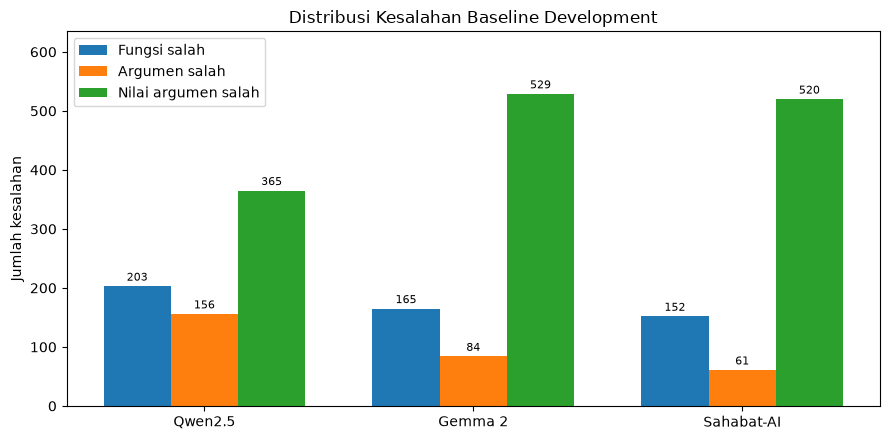

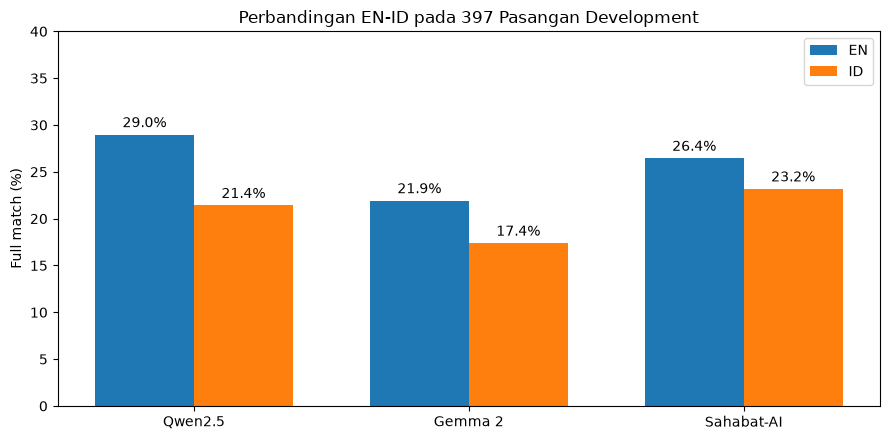


Analisis selesai.


In [31]:

# Analisis hasil baseline development

import csv
from collections import Counter, defaultdict
import matplotlib.pyplot as plt

file_hasil = OUT / "predictions_development_full_v1_verified.csv"

with file_hasil.open(encoding="utf-8-sig", newline="") as f:
    data = list(csv.DictReader(f))

assert len(data) == 2937, "Jumlah prediksi tidak sesuai."
assert len({(r["model"], r["row_key"]) for r in data}) == 2937
assert len({r["fingerprint"] for r in data}) == 1

nama_model = {
    "qwen2.5:7b-instruct": "Qwen2.5",
    "gemma2:9b-instruct-q4_K_M": "Gemma 2",
    "Supa-AI/gemma2-9b-cpt-sahabatai-v1-instruct:q4_k_m": "Sahabat-AI"
}

models = list(nama_model)

def benar(row, key):
    return str(row[key]).lower() == "true"


# A. Ringkasan ketepatan dan kesalahan

print("=== A. RINGKASAN MODEL ===")

for model in models:
    rows = [r for r in data if r["model"] == model]
    status = Counter(r["status"] for r in rows)

    fungsi = sum(benar(r, "function_correct") for r in rows)
    full = sum(benar(r, "full_match") for r in rows)

    print(f"\n{nama_model[model]}")
    print(f"Fungsi benar: {fungsi}/979 ({fungsi/979:.2%})")
    print(f"Full match: {full}/979 ({full/979:.2%})")

    for kategori, jumlah in status.most_common():
        print(f"{kategori}: {jumlah}")


# B. Perbandingan berpasangan EN-ID

print("\n=== B. PERBANDINGAN EN-ID ===")

hasil_pasangan = {}

for model in models:
    rows = [r for r in data if r["model"] == model]

    en = {
        r["record_id"]: r for r in rows
        if r["language_code"] == "en-US"
    }

    ind = {
        r["record_id"]: r for r in rows
        if r["language_code"] == "id-ID"
    }

    ids = sorted(set(en) & set(ind))
    assert len(ids) == 397

    pairs = [(en[rid], ind[rid]) for rid in ids]

    assert all(
        a["target_function"] == b["target_function"]
        for a, b in pairs
    )

    print(f"\n{nama_model[model]} | {len(pairs)} pasangan")

    for metric in ("function_correct", "full_match"):
        en_ok = sum(benar(a, metric) for a, b in pairs)
        id_ok = sum(benar(b, metric) for a, b in pairs)

        en_only = sum(
            benar(a, metric) and not benar(b, metric)
            for a, b in pairs
        )

        id_only = sum(
            benar(b, metric) and not benar(a, metric)
            for a, b in pairs
        )

        print(f"{metric}:")
        print(f"  EN: {en_ok}/397 ({en_ok/397:.2%})")
        print(f"  ID: {id_ok}/397 ({id_ok/397:.2%})")
        print(f"  Hanya EN benar: {en_only}")
        print(f"  Hanya ID benar: {id_only}")

        if metric == "full_match":
            hasil_pasangan[model] = (en_ok, id_ok)


# C. Kesalahan pemilihan fungsi

print("\n=== C. FUNGSI YANG SERING TERTUKAR ===")

for model in models:
    rows = [
        r for r in data
        if r["model"] == model
        and r["status"] == "wrong_function"
    ]

    confusion = Counter(
        (r["target_function"], r["prediction_name"])
        for r in rows
    )

    print(f"\n{nama_model[model]}")

    for (gt, pred), jumlah in confusion.most_common(5):
        print(f"{gt} -> {pred}: {jumlah}")


# D. Fungsi dengan full match terendah

print("\n=== D. FUNGSI DENGAN FULL MATCH TERENDAH ===")

for model in models:
    groups = defaultdict(list)

    for row in data:
        if row["model"] == model:
            groups[row["target_function"]].append(row)

    rates = sorted(
        (
            (name, len(rs), sum(benar(r, "full_match") for r in rs))
            for name, rs in groups.items()
            if len(rs) >= 20
        ),
        key=lambda x: (x[2] / x[1], -x[1])
    )

    print(f"\n{nama_model[model]}")

    for name, n, ok in rates[:5]:
        print(f"{name}: {ok}/{n} ({ok/n:.2%})")


# E. Grafik distribusi kesalahan

labels = [nama_model[m] for m in models]

stat = [
    Counter(
        r["status"] for r in data
        if r["model"] == model
    )
    for model in models
]

fig, ax = plt.subplots(figsize=(9, 4.5))

x = list(range(len(models)))
width = 0.25

kategori = [
    ("wrong_function", "Fungsi salah"),
    ("wrong_argument_keys", "Argumen salah"),
    ("wrong_argument_values", "Nilai argumen salah")
]

for j, (key, title) in enumerate(kategori):
    bars = ax.bar(
        [v + (j - 1) * width for v in x],
        [s[key] for s in stat],
        width,
        label=title
    )
    ax.bar_label(bars, padding=2, fontsize=8)

ax.set_xticks(x, labels)
ax.set_ylabel("Jumlah kesalahan")
ax.set_title("Distribusi Kesalahan Baseline Development")
ax.legend()
ax.set_ylim(0, max(s["wrong_argument_values"] for s in stat) * 1.2)

plt.tight_layout()
plt.savefig(OUT / "analisis_kesalahan.png", dpi=200)
plt.show()


# F. Grafik full match EN-ID pada pasangan yang sama

fig, ax = plt.subplots(figsize=(9, 4.5))

en_values = [
    hasil_pasangan[m][0] / 397 * 100
    for m in models
]

id_values = [
    hasil_pasangan[m][1] / 397 * 100
    for m in models
]

bars_en = ax.bar(
    [v - 0.18 for v in x],
    en_values, 0.36, label="EN"
)

bars_id = ax.bar(
    [v + 0.18 for v in x],
    id_values, 0.36, label="ID"
)

ax.bar_label(bars_en, fmt="%.1f%%", padding=3)
ax.bar_label(bars_id, fmt="%.1f%%", padding=3)

ax.set_xticks(x, labels)
ax.set_ylabel("Full match (%)")
ax.set_ylim(0, 40)
ax.set_title("Perbandingan EN-ID pada 397 Pasangan Development")
ax.legend()

plt.tight_layout()
plt.savefig(OUT / "perbandingan_en_id.png", dpi=200)
plt.show()

print("\nAnalisis selesai.")


In [32]:

# Audit kualitatif 30 kesalahan argumen

import csv
import json
import random
from collections import Counter

source_file = OUT / "predictions_development_full_v1_verified.csv"
audit_file = OUT / "audit_argumen_30.csv"

with source_file.open(encoding="utf-8-sig", newline="") as f:
    predictions = list(csv.DictReader(f))

assert len(predictions) == 2937
assert len({r["fingerprint"] for r in predictions}) == 1
assert len({
    (r["model"], r["row_key"]) for r in predictions
}) == 2937

# Menghubungkan hasil prediksi dengan dataset development
record_index = {
    r["row_key"]: r for r in all_rows
}

rng = random.Random(20261103)
sample = []
used_rows = set()
used_functions = set()

# Pengambilan sampel berdasarkan model, bahasa, dan jenis kesalahan
for model in MODELS:
    for language in ("en-US", "id-ID"):
        for status, jumlah in [
            ("wrong_argument_values", 3),
            ("wrong_argument_keys", 2)
        ]:
            candidates = [
                r for r in predictions
                if r["model"] == model
                and r["language_code"] == language
                and r["status"] == status
            ]

            candidates.sort(key=lambda r: r["row_key"])
            rng.shuffle(candidates)

            for _ in range(jumlah):
                # Prioritaskan fungsi yang belum terpilih
                chosen = next(
                    (
                        r for r in candidates
                        if r["row_key"] not in used_rows
                        and r["target_function"] not in used_functions
                    ),
                    None
                )

                if chosen is None:
                    chosen = next(
                        (
                            r for r in candidates
                            if r["row_key"] not in used_rows
                        ),
                        None
                    )

                if chosen is None:
                    raise ValueError("Sampel tidak mencukupi.")

                sample.append(chosen)
                used_rows.add(chosen["row_key"])
                used_functions.add(chosen["target_function"])

assert len(sample) == 30
assert len(used_rows) == 30

# Menyiapkan data audit
audit_rows = []

for i, pred in enumerate(sample, 1):
    record = record_index[pred["row_key"]]

    gt_name = next(iter(record["gt"]))

    schema = next(
        f for f in record["function"]
        if f["name"] == gt_name
    )

    properties = schema.get(
        "parameters", {}
    ).get("properties", {})

    descriptions = {
        key: meta.get("description", "")
        for key, meta in properties.items()
    }

    audit_rows.append({
        "no": i,
        "model": pred["model"],
        "record_id": pred["record_id"],
        "row_key": pred["row_key"],
        "language": pred["language_code"],
        "status": pred["status"],
        "question": record["question"],
        "target_function": gt_name,
        "ground_truth": json.dumps(
            record["gt"], ensure_ascii=False
        ),
        "prediction": pred["raw_output"],
        "parameter_descriptions": json.dumps(
            descriptions, ensure_ascii=False
        ),
        "jenis_audit": "",
        "catatan_audit": ""
    })

# Tidak menimpa file audit apabila sudah tersedia
if not audit_file.exists():
    with audit_file.open(
        "w", encoding="utf-8-sig", newline=""
    ) as f:
        writer = csv.DictWriter(
            f, fieldnames=list(audit_rows[0])
        )
        writer.writeheader()
        writer.writerows(audit_rows)

    print("File audit berhasil dibuat.")
else:
    print("File audit sudah tersedia dan tidak ditimpa.")

# Pemeriksaan file yang tersimpan
with audit_file.open(
    encoding="utf-8-sig", newline=""
) as f:
    saved = list(csv.DictReader(f))

assert len(saved) == 30

print("\n=== RINGKASAN SAMPEL AUDIT ===")
print("Jumlah prediksi:", len(saved))
print("Jenis fungsi:", len(set(
    r["target_function"] for r in saved
)))

for model in MODELS:
    rows = [r for r in saved if r["model"] == model]

    print("\n", model)
    print("EN:", sum(r["language"] == "en-US" for r in rows))
    print("ID:", sum(r["language"] == "id-ID" for r in rows))
    print("Status:", dict(Counter(r["status"] for r in rows)))

print("\n=== CONTOH DATA AUDIT ===")

for r in saved[:3]:
    print("\n" + "=" * 60)
    print("ID:", r["record_id"])
    print("Bahasa:", r["language"])
    print("Model:", r["model"])
    print("Pertanyaan:", r["question"])
    print("GT:", r["ground_truth"])
    print("Prediksi:", r["prediction"])

print("\nLokasi file:", audit_file)


File audit berhasil dibuat.

=== RINGKASAN SAMPEL AUDIT ===
Jumlah prediksi: 30
Jenis fungsi: 29

 qwen2.5:7b-instruct
EN: 5
ID: 5
Status: {'wrong_argument_values': 6, 'wrong_argument_keys': 4}

 gemma2:9b-instruct-q4_K_M
EN: 5
ID: 5
Status: {'wrong_argument_values': 6, 'wrong_argument_keys': 4}

 Supa-AI/gemma2-9b-cpt-sahabatai-v1-instruct:q4_k_m
EN: 5
ID: 5
Status: {'wrong_argument_values': 6, 'wrong_argument_keys': 4}

=== CONTOH DATA AUDIT ===

ID: 997
Bahasa: en-US
Model: qwen2.5:7b-instruct
Pertanyaan: turn the living room's light off
GT: {"iot.hue_lightoff": {"house_place": ["living room's"], "device_type": [""], "time": ["", "now"]}}
Prediksi: {"name":"iot.hue_lightoff","arguments":{"house_place":"living room"}}

ID: 379
Bahasa: en-US
Model: qwen2.5:7b-instruct
Pertanyaan: i want the music to be saved can you do it for me
GT: {"music.likeness": {"artist_name": [""], "playlist_name": [""]}}
Prediksi: {"name":"music.likeness","arguments":{"artist_name":"unknown"}}

ID: 2075
Bahas